<a href="https://colab.research.google.com/github/prettlee/pedestrian-tracking-forecasting/blob/main/mot17_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
tar = "/content/drive/MyDrive/mot17/mot17_frcnn.tar"
os.makedirs("/content/data/MOT17/train", exist_ok=True)

if os.path.exists(tar) and os.path.getsize(tar) > 1e8:
    print("Restoring from Drive...")
    !tar -xf {tar} -C /content/data/MOT17/train
else:
    print("No usable Drive copy, downloading...")
    !wget -q -O /content/MOT17.zip "https://motchallenge.net/data/MOT17.zip"
    !unzip -q -o /content/MOT17.zip 'MOT17/train/*' -d /content/data

!ls /content/data/MOT17/train

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
No usable Drive copy, downloading...
MOT17-02-DPM	MOT17-04-SDP	MOT17-09-FRCNN	MOT17-11-DPM	MOT17-13-SDP
MOT17-02-FRCNN	MOT17-05-DPM	MOT17-09-SDP	MOT17-11-FRCNN
MOT17-02-SDP	MOT17-05-FRCNN	MOT17-10-DPM	MOT17-11-SDP
MOT17-04-DPM	MOT17-05-SDP	MOT17-10-FRCNN	MOT17-13-DPM
MOT17-04-FRCNN	MOT17-09-DPM	MOT17-10-SDP	MOT17-13-FRCNN


pedestrian boxes: 18581 | unique people: 62


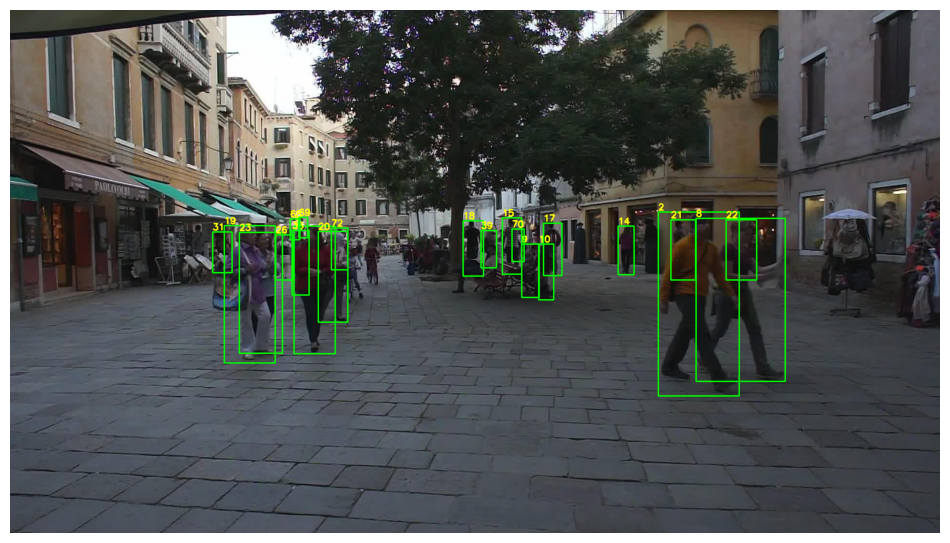

In [ ]:
import cv2, pandas as pd
import matplotlib.pyplot as plt

seq = "/content/data/MOT17/train/MOT17-02-FRCNN"
cols = ["frame", "id", "x", "y", "w", "h", "conf", "cls", "vis"]
gt = pd.read_csv(f"{seq}/gt/gt.txt", header=None, names=cols)
gt = gt[(gt.conf == 1) & (gt.cls == 1)]   # keep valid pedestrian boxes only

frame = 1
img = cv2.cvtColor(cv2.imread(f"{seq}/img1/{frame:06d}.jpg"), cv2.COLOR_BGR2RGB)
for _, r in gt[gt.frame == frame].iterrows():
    x, y, w, h = int(r.x), int(r.y), int(r.w), int(r.h)
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(img, str(int(r.id)), (x, y - 4),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)

plt.figure(figsize=(12, 7)); plt.imshow(img); plt.axis("off")
print("pedestrian boxes:", len(gt), "| unique people:", gt.id.nunique())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


(np.float64(-0.5), np.float64(1919.5), np.float64(1079.5), np.float64(-0.5))

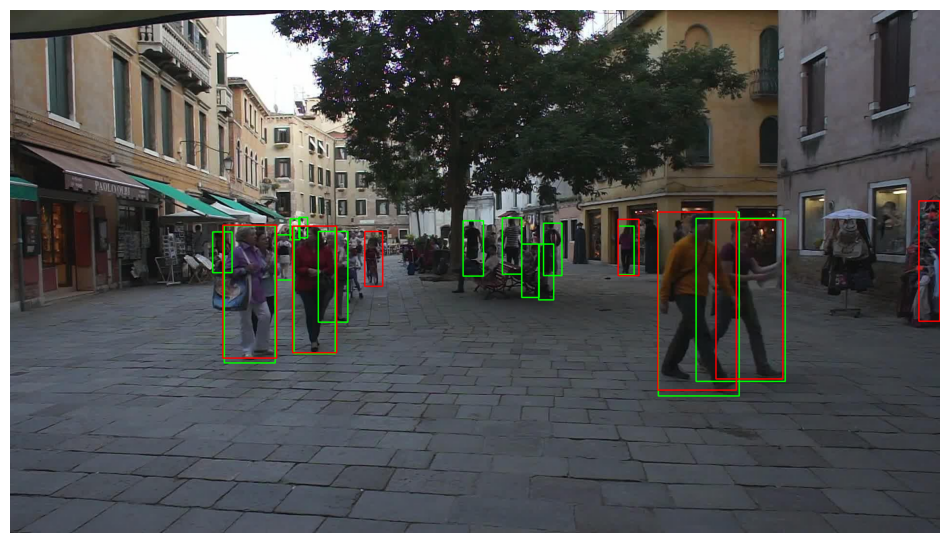

In [ ]:
!pip -q install ultralytics
import numpy as np
from ultralytics import YOLO

model = YOLO("yolov8n.pt")   # small pretrained COCO model

def gt_boxes(frame, min_vis=0.3):
    g = gt[(gt.frame == frame) & (gt.vis >= min_vis)]
    return np.stack([g.x, g.y, g.x + g.w, g.y + g.h], 1) if len(g) else np.zeros((0, 4))

def detect(frame, conf=0.25):
    r = model.predict(f"{seq}/img1/{frame:06d}.jpg", classes=[0], conf=conf, verbose=False)[0]
    return r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()

frame = 1
img = cv2.cvtColor(cv2.imread(f"{seq}/img1/{frame:06d}.jpg"), cv2.COLOR_BGR2RGB)
for x1, y1, x2, y2 in gt_boxes(frame):
    cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
for (x1, y1, x2, y2), s in zip(*detect(frame)):
    cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), 2)
plt.figure(figsize=(12, 7)); plt.imshow(img); plt.axis("off")

In [ ]:
from scipy.optimize import linear_sum_assignment

def iou(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)

def evaluate(min_vis, conf=0.25):
    tp = fp = fn = 0
    for f in range(1, 601, 10):
        g, (d, _) = gt_boxes(f, min_vis), detect(f, conf)
        if len(g) == 0 or len(d) == 0:
            fn += len(g); fp += len(d); continue
        m = iou(d, g)
        r, c = linear_sum_assignment(-m)
        hit = int((m[r, c] >= 0.5).sum())
        tp += hit; fp += len(d) - hit; fn += len(g) - hit
    return tp / (tp + fp + 1e-9), tp / (tp + fn + 1e-9)

for v in [0.0, 0.3, 0.6]:
    p, r = evaluate(v)
    print(f"min_vis={v}: precision={p:.2f}  recall={r:.2f}")

min_vis=0.0: precision=0.73  recall=0.23
min_vis=0.3: precision=0.69  recall=0.45
min_vis=0.6: precision=0.62  recall=0.56


In [ ]:
import time

def detect(frame, conf=0.25, imgsz=640, mdl=None):
    r = (mdl or model).predict(f"{seq}/img1/{frame:06d}.jpg", classes=[0],
                               conf=conf, imgsz=imgsz, verbose=False)[0]
    return r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()

def evaluate(min_vis, conf=0.25, imgsz=640, mdl=None):
    tp = fp = fn = 0
    frames = range(1, 601, 10)
    t0 = time.time()
    for f in frames:
        g, (d, _) = gt_boxes(f, min_vis), detect(f, conf, imgsz, mdl)
        if len(g) == 0 or len(d) == 0:
            fn += len(g); fp += len(d); continue
        m = iou(d, g)
        r, c = linear_sum_assignment(-m)
        hit = int((m[r, c] >= 0.5).sum())
        tp += hit; fp += len(d) - hit; fn += len(g) - hit
    ms = (time.time() - t0) / len(frames) * 1000
    return tp / (tp + fp + 1e-9), tp / (tp + fn + 1e-9), ms

for name in ["yolov8n.pt", "yolov8s.pt", "yolov8m.pt"]:
    mdl = YOLO(name)
    for sz in [640, 1280]:
        p, r, ms = evaluate(0.3, imgsz=sz, mdl=mdl)
        print(f"{name} @ {sz}: precision={p:.2f} recall={r:.2f} {ms:.0f} ms/frame")

yolov8n.pt @ 640: precision=0.69 recall=0.45 34 ms/frame
yolov8n.pt @ 1280: precision=0.65 recall=0.66 29 ms/frame
yolov8s.pt @ 640: precision=0.72 recall=0.57 29 ms/frame
yolov8s.pt @ 1280: precision=0.62 recall=0.69 49 ms/frame
yolov8m.pt @ 640: precision=0.70 recall=0.62 37 ms/frame
yolov8m.pt @ 1280: precision=0.65 recall=0.72 94 ms/frame


## Detection benchmark (MOT17-02, every 10th of first 600 frames, IoU 0.5, min_vis=0.3)

**T4 GPU** (ms/frame includes image loading; first row includes GPU warm-up)

| Model | Input size | Precision | Recall | ms/frame |
|---|---|---|---|---|
| yolov8n | 640 | 0.69 | 0.45 | 34 |
| yolov8n | 1280 | 0.65 | 0.66 | 29 |
| yolov8s | 640 | 0.72 | 0.57 | 29 |
| yolov8s | 1280 | 0.62 | 0.69 | 49 |
| yolov8m | 640 | 0.70 | 0.62 | 37 |
| yolov8m | 1280 | 0.65 | 0.72 | 94 |

**CPU** (same setup, earlier run)

| Model | Input size | Precision | Recall | ms/frame |
|---|---|---|---|---|
| yolov8n | 640 | 0.69 | 0.45 | 153 |
| yolov8n | 1280 | 0.65 | 0.66 | 504 |
| yolov8s | 640 | 0.72 | 0.57 | 459 |
| yolov8s | 1280 | 0.62 | 0.69 | 1473 |
| yolov8m | 640 | 0.70 | 0.62 | 947 |

Takeaway: input resolution mattered more than model size. yolov8n at 1280 gave the best recall per millisecond.

## Tracking: SORT vs ByteTrack-style (yolov8n @ 1280, max_age=30)

| Sequence | Method | Tracks (true people) | MOTA | IDF1 | ID switches | Fragmentations |
|---|---|---|---|---|---|---|
| MOT17-02* | SORT | 172 (62) | 0.400 | 0.519 | 87 | 206 |
| MOT17-02* | ByteTrack-style | 94 | 0.376 | 0.538 | 43 | 58 |
| MOT17-09 | SORT | 113 (26) | 0.457 | 0.530 | 57 | 28 |
| MOT17-09 | ByteTrack-style | 85 | 0.430 | 0.541 | 36 | 20 |
| MOT17-04 | SORT | 251 (83) | 0.593 | 0.584 | 180 | 703 |
| MOT17-04 | ByteTrack-style | 111 | 0.619 | 0.660 | 61 | 291 |

*Settings were tuned on MOT17-02, so its numbers are optimistic. The other two used frozen settings.